# COMM075 — Adult Census Income: Data Preparation Pipeline
**Dataset:** https://www.kaggle.com/datasets/uciml/adult-census-income  
**Methodology:** CRISP-DM  

This notebook covers:
1. Imports
2. Data Loading & Initial Inspection
3. Data Quality Assessment
4. Missing Value Handling
5. Feature Selection & Redundancy Removal
6. Target Variable Encoding
7. Outlier Detection
8. Categorical Feature Encoding
9. Feature Matrix & Scaling
10. Train / Test Split
11. Exploratory Data Visualisation
12. Save Prepared Data
13. Summary Report

## 1. Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import os

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")

# Output directory for plots
os.makedirs("output_plots", exist_ok=True)

print("Libraries loaded successfully.")

Libraries loaded successfully.


## 2. Data Loading & Initial Inspection
Load the dataset and get a first look at shape, column names, data types and the first few rows.

In [2]:
df = pd.read_csv("adult.csv")

print(f"Shape (rows, cols): {df.shape}")
print(f"\nColumn names:\n{list(df.columns)}")
print(f"\nData types:\n{df.dtypes}")

Shape (rows, cols): (32561, 15)

Column names:
['age', 'workclass', 'fnlwgt', 'education', 'education.num', 'marital.status', 'occupation', 'relationship', 'race', 'sex', 'capital.gain', 'capital.loss', 'hours.per.week', 'native.country', 'income']

Data types:
age                int64
workclass         object
fnlwgt             int64
education         object
education.num      int64
marital.status    object
occupation        object
relationship      object
race              object
sex               object
capital.gain       int64
capital.loss       int64
hours.per.week     int64
native.country    object
income            object
dtype: object


In [3]:
# First 5 rows
df.head()

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


## 3. Data Quality Assessment
Check for missing values (encoded as `?` in this dataset), duplicates and class balance.

In [4]:
# Replace '?' with NaN so pandas can detect them properly
# The Kaggle CSV version often includes a leading space: ' ?'
df.replace(" ?", np.nan, inplace=True)
df.replace("?", np.nan, inplace=True)

# Missing values report
missing = df.isnull().sum()
missing_pct = (df.isnull().sum() / len(df)) * 100
missing_report = pd.DataFrame({
    "Missing Count": missing,
    "Missing %": missing_pct.round(2)
}).query("`Missing Count` > 0")

print("Missing values (after replacing '?'):")
print(missing_report)

Missing values (after replacing '?'):
                Missing Count  Missing %
workclass                1836       5.64
occupation               1843       5.66
native.country            583       1.79


In [5]:
# Duplicate rows
dupes = df.duplicated().sum()
print(f"Duplicate rows: {dupes}")

Duplicate rows: 24


In [6]:
# Target class balance
print("Target class distribution:")
print(df["income"].value_counts())
print()
print(df["income"].value_counts(normalize=True).round(3))

Target class distribution:
income
<=50K    24720
>50K      7841
Name: count, dtype: int64

income
<=50K    0.759
>50K     0.241
Name: proportion, dtype: float64


In [7]:
# Summary statistics — numeric features
df.describe()

,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week
count,32561.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,1.897784e+05,10.080679,1077.648844,87.303830,40.437456
std,13.640433,1.055500e+05,2.572720,7385.292085,402.960219,12.347429
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.370510e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000


## 4. Missing Value Handling
**Strategy:** Drop rows containing any missing value.  
**Justification:** Only ~5.6% of rows are affected. Dropping avoids introducing bias through imputation on a large (48K row) dataset.

In [8]:
rows_before = len(df)

df.dropna(inplace=True)
df.reset_index(drop=True, inplace=True)

rows_after = len(df)
print(f"Rows before: {rows_before}")
print(f"Rows after dropping NaN rows: {rows_after}")
print(f"Rows removed: {rows_before - rows_after} ({(rows_before - rows_after)/rows_before*100:.1f}%)")

Rows before: 32561
Rows after dropping NaN rows: 30162
Rows removed: 2399 (7.4%)


In [9]:
# Drop duplicate rows
df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)
print(f"Rows after dropping duplicates: {len(df)}")

Rows after dropping duplicates: 30139


## 5. Feature Selection & Redundancy Removal
Two features are removed before modelling:

| Feature | Reason for removal |
|---|---|
| `education` | Redundant — `education.num` encodes the same information as an ordinal integer |
| `fnlwgt` | Census sampling weight — a survey design variable, not a predictor of individual income |

In [10]:
df.drop(columns=["education", "fnlwgt"], inplace=True)

print(f"Remaining features ({len(df.columns)}):")
print(list(df.columns))

Remaining features (13):
['age', 'workclass', 'education.num', 'marital.status', 'occupation', 'relationship', 'race', 'sex', 'capital.gain', 'capital.loss', 'hours.per.week', 'native.country', 'income']


## 6. Target Variable Encoding
Map the string target to a binary integer:  
- `<=50K` → **0**  
- `>50K`  → **1**

In [11]:
# Strip whitespace (common in the Kaggle version)
df["income"] = df["income"].str.strip()
df["income"] = df["income"].map({"<=50K": 0, ">50K": 1})

print(f"Unique target values: {df['income'].unique()}")
print(f"\nClass balance after encoding:")
print(df["income"].value_counts())

Unique target values: [0 1]

Class balance after encoding:
income
0    22633
1     7506
Name: count, dtype: int64


## 7. Outlier Detection
Use the IQR method to identify outliers in all numeric features.  
`capital.gain` and `capital.loss` are extremely right-skewed (most values are 0) — we apply a **log1p transform** to compress extreme values.

In [12]:
numeric_cols = ["age", "education.num", "capital.gain", "capital.loss", "hours.per.week"]

print(f"{'Feature':<20} {'Q1':>6} {'Q3':>6} {'IQR':>6}  {'Lower':>7} {'Upper':>7}  {'Outliers':>8}")
print("-" * 70)
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    n_outliers = ((df[col] < lower) | (df[col] > upper)).sum()
    print(f"{col:<20} {Q1:>6.1f} {Q3:>6.1f} {IQR:>6.1f}  {lower:>7.1f} {upper:>7.1f}  {n_outliers:>8}")

Feature                  Q1     Q3    IQR    Lower   Upper  Outliers
----------------------------------------------------------------------
age                    28.0   47.0   19.0     -0.5    75.5       168
education.num           9.0   13.0    4.0      3.0    19.0       193
capital.gain            0.0    0.0    0.0      0.0     0.0      2538
capital.loss            0.0    0.0    0.0      0.0     0.0      1427
hours.per.week         40.0   45.0    5.0     32.5    52.5      7947


In [13]:
# Apply log1p transform to right-skewed capital features
df["capital.gain"] = np.log1p(df["capital.gain"])
df["capital.loss"] = np.log1p(df["capital.loss"])

print("log1p transform applied to capital.gain and capital.loss.")

log1p transform applied to capital.gain and capital.loss.


## 8. Categorical Feature Encoding
Two encoding strategies are produced:

| Strategy | Use case |
|---|---|
| **Label Encoding** | Tree-based models (Decision Tree, Naive Bayes, Random Forest) |
| **One-Hot Encoding** | Distance / linear models (kNN, SVM, Neural Nets) — avoids false ordinal ordering |

In [14]:
categorical_cols = [
    "workclass", "marital.status", "occupation",
    "relationship", "race", "sex", "native.country"
]

# Strip whitespace from all categorical columns
for col in categorical_cols:
    df[col] = df[col].str.strip()

# Label Encoding
le = LabelEncoder()
df_encoded = df.copy()

for col in categorical_cols:
    df_encoded[col] = le.fit_transform(df_encoded[col])
    print(f"  {col:<20} → {df[col].nunique()} unique categories encoded")

  workclass            → 7 unique categories encoded
  marital.status       → 7 unique categories encoded
  occupation           → 14 unique categories encoded
  relationship         → 6 unique categories encoded
  race                 → 5 unique categories encoded
  sex                  → 2 unique categories encoded
  native.country       → 41 unique categories encoded


In [15]:
# One-Hot Encoding (for distance/linear models)
df_ohe = pd.get_dummies(df.drop(columns=["income"]), columns=categorical_cols)
print(f"One-hot encoded feature count: {df_ohe.shape[1]} columns")

One-hot encoded feature count: 87 columns


## 9. Feature Matrix & Scaling
Apply **StandardScaler** (zero mean, unit variance).  
This is required for SVM, kNN, and Neural Nets, and harmless for tree-based models.

In [16]:
X = df_encoded.drop(columns=["income"])
y = df_encoded["income"]
X_ohe_full = df_ohe.copy()

scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

print(f"Feature matrix shape: {X_scaled.shape}")
print(f"\nMean (should be ≈ 0):")
print(X_scaled.mean().round(3))
print(f"\nStd (should be ≈ 1):")
print(X_scaled.std().round(3))

Feature matrix shape: (30139, 12)

Mean (should be ≈ 0):
age               0.0
workclass        -0.0
education.num     0.0
marital.status    0.0
occupation        0.0
relationship     -0.0
race              0.0
sex              -0.0
capital.gain      0.0
capital.loss      0.0
hours.per.week   -0.0
native.country   -0.0
dtype: float64

Std (should be ≈ 1):
age               1.0
workclass         1.0
education.num     1.0
marital.status    1.0
occupation        1.0
relationship      1.0
race              1.0
sex               1.0
capital.gain      1.0
capital.loss      1.0
hours.per.week    1.0
native.country    1.0
dtype: float64


## 10. Train / Test Split
**80/20 stratified split** — preserves the class ratio in both sets.  
Both label-encoded and OHE versions are split.

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set:  {X_train.shape[0]} rows")
print(f"Test set:      {X_test.shape[0]} rows")
print(f"\nTraining class balance:")
print(y_train.value_counts(normalize=True).round(3))
print(f"\nTest class balance:")
print(y_test.value_counts(normalize=True).round(3))

Training set:  24111 rows
Test set:      6028 rows

Training class balance:
income
0    0.751
1    0.249
Name: proportion, dtype: float64

Test class balance:
income
0    0.751
1    0.249
Name: proportion, dtype: float64


In [18]:
# OHE split (for SVM, kNN, Neural Nets)
X_ohe_scaled = pd.DataFrame(scaler.fit_transform(X_ohe_full), columns=X_ohe_full.columns)
X_train_ohe, X_test_ohe, _, _ = train_test_split(
    X_ohe_scaled, y, test_size=0.2, random_state=42, stratify=y
)

print(f"OHE training set: {X_train_ohe.shape}")
print(f"OHE test set:     {X_test_ohe.shape}")

OHE training set: (24111, 87)
OHE test set:     (6028, 87)


## 11. Exploratory Data Visualisation
Seven charts covering class balance, feature distributions, skew correction, correlations and relationships with the target.

In [19]:
sns.set_theme(style="whitegrid")

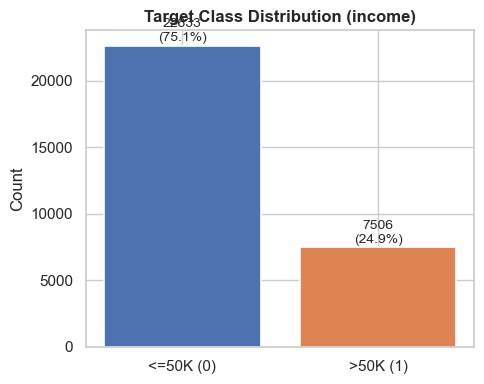

In [20]:
# 11a — Target class distribution
fig, ax = plt.subplots(figsize=(5, 4))
labels = ["<=50K (0)", ">50K (1)"]
counts = y.value_counts().sort_index()
bars = ax.bar(labels, counts, color=["#4C72B0", "#DD8452"], edgecolor="white", linewidth=1.2)
for bar, count in zip(bars, counts):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 100,
            f"{count}\n({count/len(y)*100:.1f}%)", ha="center", va="bottom", fontsize=10)
ax.set_title("Target Class Distribution (income)", fontweight="bold")
ax.set_ylabel("Count")
plt.tight_layout()
plt.savefig("output_plots/01_class_distribution.png", dpi=150)
plt.show()

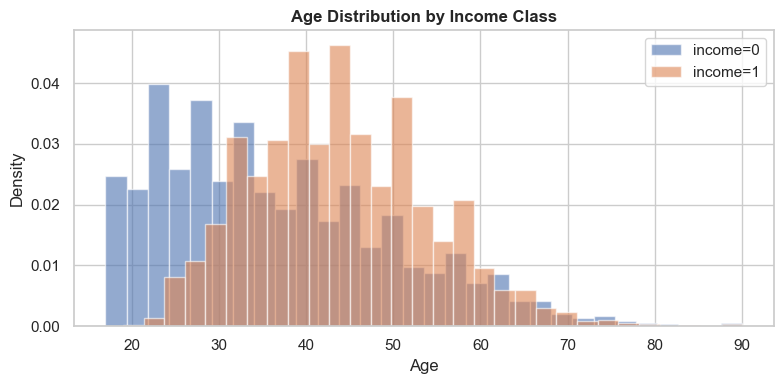

In [21]:
# 11b — Age distribution by income class
fig, ax = plt.subplots(figsize=(8, 4))
for label, grp in df.groupby("income"):
    ax.hist(grp["age"], bins=30, alpha=0.6, label=f"income={label}", density=True)
ax.set_title("Age Distribution by Income Class", fontweight="bold")
ax.set_xlabel("Age")
ax.set_ylabel("Density")
ax.legend()
plt.tight_layout()
plt.savefig("output_plots/02_age_by_income.png", dpi=150)
plt.show()

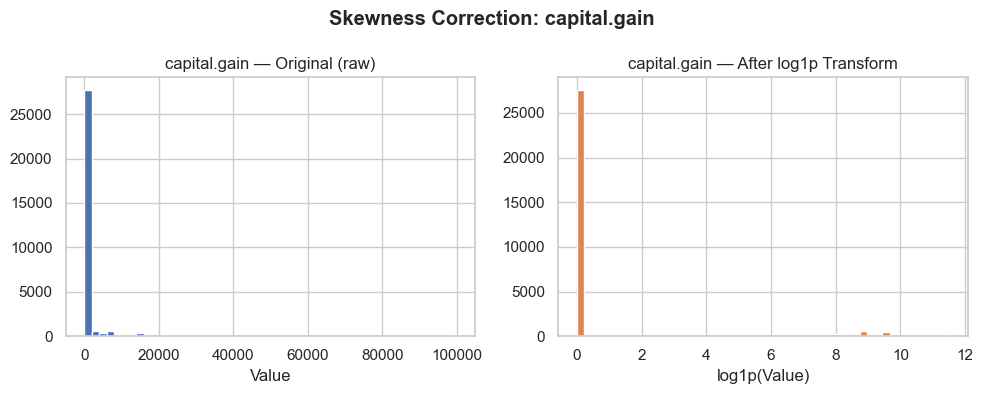

In [22]:
# 11c — Skewness correction: capital.gain before vs after log1p
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
original = pd.read_csv("adult.csv").replace(" ?", np.nan).replace("?", np.nan).dropna()
axes[0].hist(original["capital.gain"], bins=50, color="#4C72B0", edgecolor="white")
axes[0].set_title("capital.gain — Original (raw)")
axes[0].set_xlabel("Value")
axes[1].hist(df["capital.gain"], bins=50, color="#DD8452", edgecolor="white")
axes[1].set_title("capital.gain — After log1p Transform")
axes[1].set_xlabel("log1p(Value)")
plt.suptitle("Skewness Correction: capital.gain", fontweight="bold")
plt.tight_layout()
plt.savefig("output_plots/03_capital_gain_transform.png", dpi=150)
plt.show()

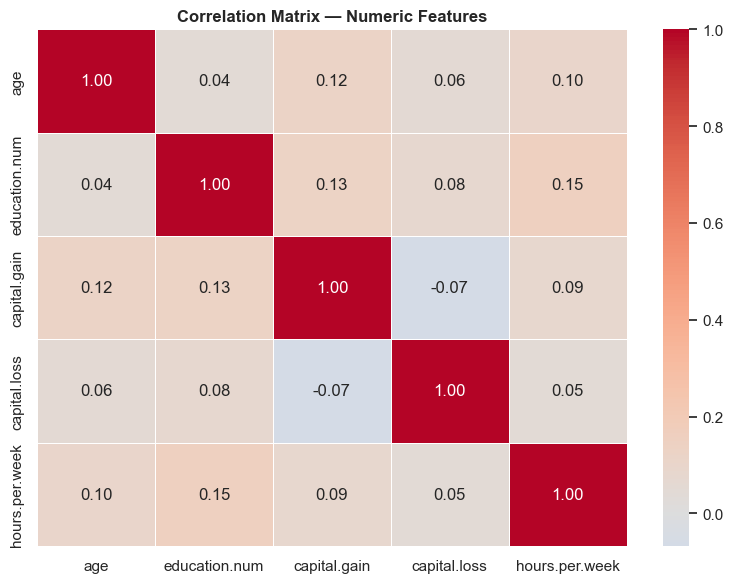

In [23]:
# 11d — Correlation heatmap (numeric features)
fig, ax = plt.subplots(figsize=(8, 6))
corr = X_scaled[["age", "education.num", "capital.gain", "capital.loss", "hours.per.week"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax, linewidths=0.5)
ax.set_title("Correlation Matrix — Numeric Features", fontweight="bold")
plt.tight_layout()
plt.savefig("output_plots/04_correlation_heatmap.png", dpi=150)
plt.show()

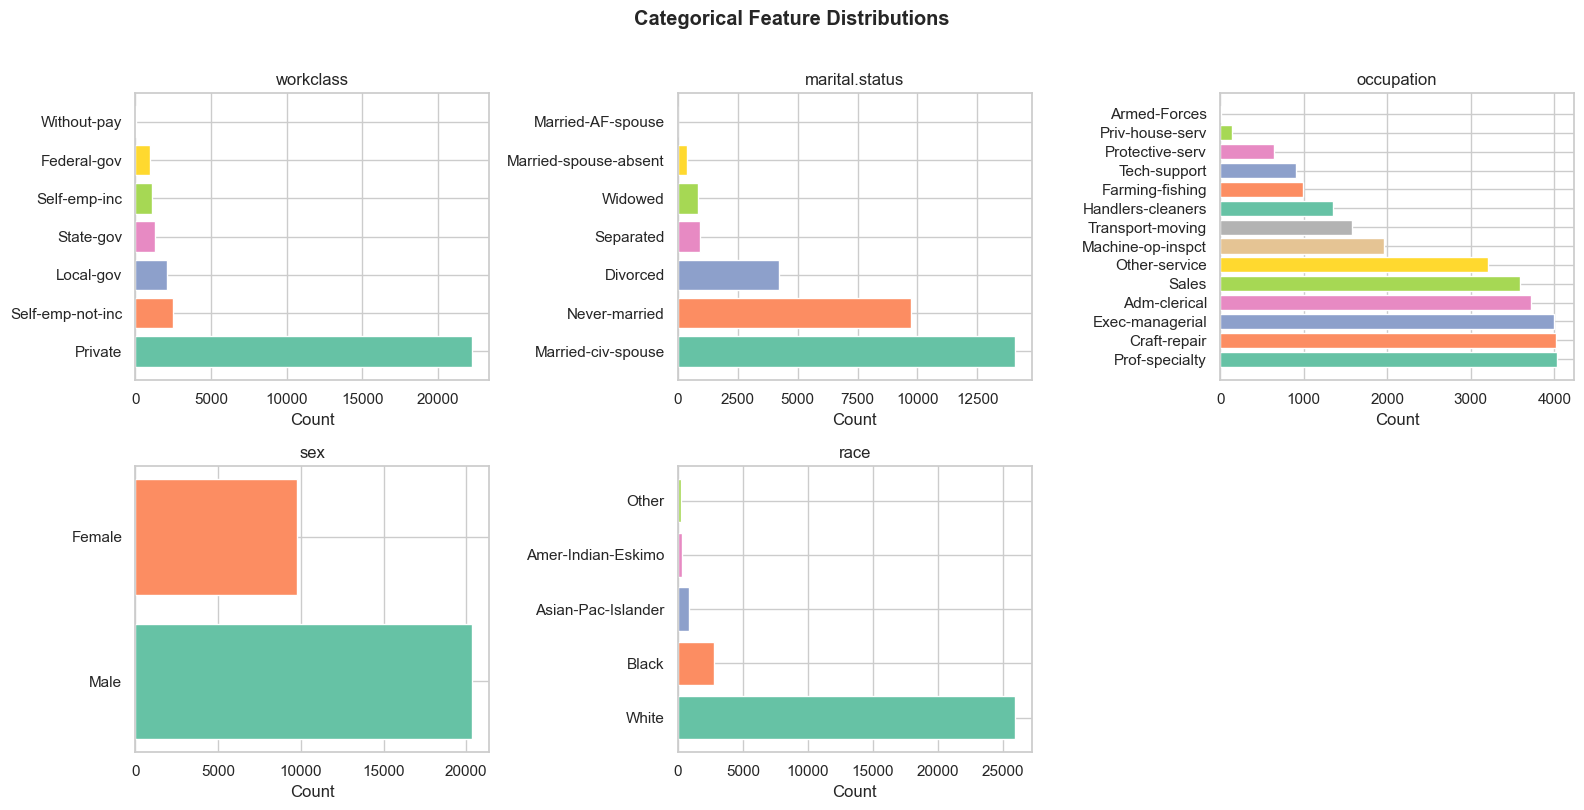

In [24]:
# 11e — Categorical feature distributions
cat_display = ["workclass", "marital.status", "occupation", "sex", "race"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()
for i, col in enumerate(cat_display):
    vc = df[col].value_counts()
    axes[i].barh(vc.index, vc.values, color=sns.color_palette("Set2", len(vc)))
    axes[i].set_title(col)
    axes[i].set_xlabel("Count")
axes[-1].set_visible(False)
plt.suptitle("Categorical Feature Distributions", fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig("output_plots/05_categorical_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

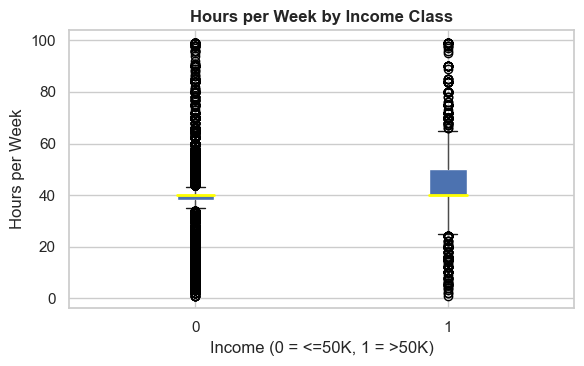

In [25]:
# 11f — Hours per week by income (boxplot)
fig, ax = plt.subplots(figsize=(6, 4))
df.boxplot(column="hours.per.week", by="income", ax=ax,
           patch_artist=True,
           boxprops=dict(facecolor="#4C72B0", color="white"),
           medianprops=dict(color="yellow", linewidth=2))
ax.set_title("Hours per Week by Income Class", fontweight="bold")
ax.set_xlabel("Income (0 = <=50K, 1 = >50K)")
ax.set_ylabel("Hours per Week")
plt.suptitle("")
plt.tight_layout()
plt.savefig("output_plots/06_hours_by_income_boxplot.png", dpi=150)
plt.show()

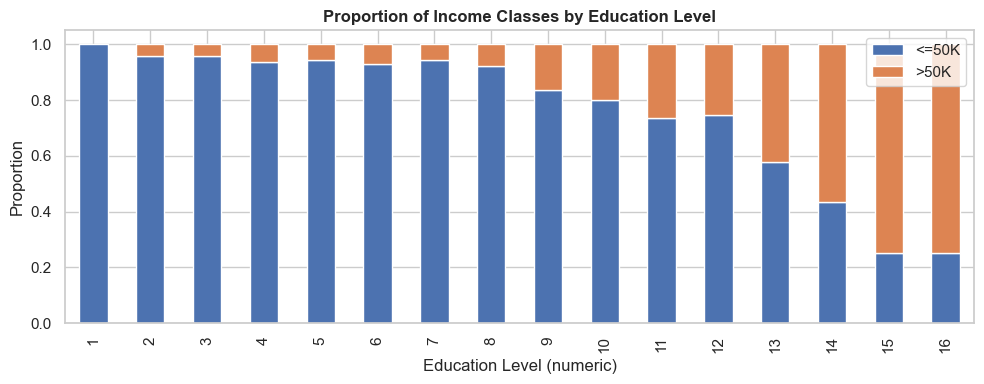

In [26]:
# 11g — Education level vs income (stacked bar)
edu_income = df.groupby(["education.num", "income"]).size().unstack(fill_value=0)
edu_income_pct = edu_income.div(edu_income.sum(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(10, 4))
edu_income_pct.plot(kind="bar", stacked=True, ax=ax,
                    color=["#4C72B0", "#DD8452"], edgecolor="white")
ax.set_title("Proportion of Income Classes by Education Level", fontweight="bold")
ax.set_xlabel("Education Level (numeric)")
ax.set_ylabel("Proportion")
ax.legend(["<=50K", ">50K"])
plt.tight_layout()
plt.savefig("output_plots/07_education_income_stacked.png", dpi=150)
plt.show()

## 12. Save Prepared Data
Export train/test splits as CSV files ready for model development.

In [27]:
# Label-encoded version (tree-based models)
X_train.to_csv("X_train.csv", index=False)
X_test.to_csv("X_test.csv", index=False)
y_train.to_csv("y_train.csv", index=False)
y_test.to_csv("y_test.csv", index=False)

# One-hot encoded version (SVM, kNN, Neural Nets)
X_train_ohe.to_csv("X_train_ohe.csv", index=False)
X_test_ohe.to_csv("X_test_ohe.csv", index=False)

print("Saved:")
print("  X_train.csv, X_test.csv, y_train.csv, y_test.csv  (label-encoded)")
print("  X_train_ohe.csv, X_test_ohe.csv                   (one-hot encoded)")

Saved:
  X_train.csv, X_test.csv, y_train.csv, y_test.csv  (label-encoded)
  X_train_ohe.csv, X_test_ohe.csv                   (one-hot encoded)


## 13. Summary Report

In [28]:
print("=" * 60)
print("DATA PREPARATION SUMMARY")
print("=" * 60)
print(f"  Original dataset shape:          {rows_before} rows × 15 cols")
print(f"  After cleaning (NaN + dupes):    {len(df)} rows × {len(df.columns)} cols")
print(f"  Features dropped:                education, fnlwgt")
print(f"  Missing value strategy:          Drop rows (~5.6% of data)")
print(f"  Skew correction:                 log1p on capital.gain, capital.loss")
print(f"  Encoding (label):                {len(categorical_cols)} categorical features")
print(f"  Encoding (OHE):                  {df_ohe.shape[1]} features after OHE")
print(f"  Scaling:                         StandardScaler (zero mean, unit variance)")
print(f"  Train/test split:                80% / 20% (stratified)")
print(f"  Training samples:                {len(X_train)}")
print(f"  Test samples:                    {len(X_test)}")
print(f"  Class imbalance (train):         {y_train.value_counts(normalize=True).round(3).to_dict()}")
print("=" * 60)

DATA PREPARATION SUMMARY
  Original dataset shape:          32561 rows × 15 cols
  After cleaning (NaN + dupes):    30139 rows × 13 cols
  Features dropped:                education, fnlwgt
  Missing value strategy:          Drop rows (~5.6% of data)
  Skew correction:                 log1p on capital.gain, capital.loss
  Encoding (label):                7 categorical features
  Encoding (OHE):                  87 features after OHE
  Scaling:                         StandardScaler (zero mean, unit variance)
  Train/test split:                80% / 20% (stratified)
  Training samples:                24111
  Test samples:                    6028
  Class imbalance (train):         {0: 0.751, 1: 0.249}


In [29]:
# Quick check on X_train
print("X_train — first 5 rows:")
display(X_train.head())
print("\nX_train — describe:")
display(X_train.describe())

X_train — first 5 rows:


,age,workclass,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country
10521,-1.252110,-0.208980,-0.048076,0.948085,1.498681,0.987452,0.385108,0.692725,-0.301139,-0.222804,-0.078031,0.264666
10894,0.804060,1.887014,-0.048076,-0.386977,-0.982709,-0.885672,0.385108,0.692725,-0.301139,-0.222804,2.009032,-1.046199
9731,-0.871338,-0.208980,2.306068,0.948085,-1.478987,0.987452,0.385108,-1.443574,-0.301139,-0.222804,-0.078031,0.264666
7348,1.032523,-2.304975,-0.440434,-1.722039,-1.478987,-0.261297,0.385108,-1.443574,-0.301139,-0.222804,-0.078031,0.264666
16967,1.413296,0.839017,-0.048076,-0.386977,1.250542,-0.885672,0.385108,0.692725,-0.301139,-0.222804,0.756794,0.264666



X_train — describe:


,age,workclass,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country
count,24111.000000,24111.000000,24111.000000,24111.000000,24111.000000,24111.000000,24111.000000,24111.000000,24111.000000,24111.000000,24111.000000,24111.000000
mean,0.003360,0.002349,0.000043,-0.000346,0.003970,-0.000707,-0.001285,-0.001565,0.000644,-0.002015,-0.000882,-0.004462
std,1.002618,1.002580,1.000324,1.004402,1.000620,0.998218,1.002188,1.000607,1.001517,0.995766,0.998094,1.010111
min,-1.632883,-2.304975,-3.579294,-1.722039,-1.478987,-0.885672,-4.406618,-1.443574,-0.301139,-0.222804,-3.333850,-5.961943
25%,-0.795183,-0.208980,-0.440434,-0.386977,-0.982709,-0.885672,0.385108,-1.443574,-0.301139,-0.222804,-0.078031,0.264666
50%,-0.109793,-0.208980,-0.048076,-0.386977,0.009847,-0.261297,0.385108,0.692725,-0.301139,-0.222804,-0.078031,0.264666
75%,0.651751,-0.208980,1.128996,0.948085,0.754264,0.987452,0.385108,0.692725,-0.301139,-0.222804,0.339381,0.264666
max,3.926393,3.983008,2.306068,2.283147,1.746819,2.236200,0.385108,0.692725,4.357448,5.028976,4.847438,0.592383
